In [1]:
from iqtools import *
filename = '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.52.966.tiq'

iq_data = TIQData(filename)
print(iq_data.center)
print(iq_data.nsamples_total)
iq_data.read_samples(112000000,0)

iq_data.window='hamming'
iq_data.method='mtm'

8497000000.0
112000000


In [2]:

# Suppress TensorFlow GPU-related warnings
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers

# NumPy for numerical operations
import numpy as np

# Matplotlib for plotting
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 150  # High-res display


In [3]:
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers


In [4]:
# NumPy for numerical operations
import numpy as np

# Matplotlib for plotting
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 150  # High-res display


In [5]:
# network visualisation and inspection
import tensorboard
import datetime
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, losses
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Model

In [6]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Your TIQData class should be defined or imported somewhere here
# Assuming it provides .read_samples() and .data_array and .fs as in your example

# ─── 1) PARAMETERS ────────────────────────────────────────────────────────────
file_list = [
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.44.849.tiq',
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.28.613.tiq',
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.22.40.034.tiq',
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.36.730.tiq',
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.04.270.tiq',
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.12.385.tiq',
    '/Users/swarangee/Desktop/Gravnet/IQDataFile-2024.04.18.19.20.20.500.tiq']

chunk_size = 1024  # FFT length
navg = 1           # number of FFTs to average per PSD

# ─── 2) SETUP SAMPLING RATE AND BAND MASK ─────────────────────────────────────
iq = TIQData(file_list[0])
iq.read_samples(112000000, 0)
fs = iq.fs  # sampling rate

freqs = np.fft.fftshift(np.fft.fftfreq(chunk_size, d=1/fs))
band_mask = (freqs >= 0.8e6) & (freqs <= 1.86e6)
print(f"Mask will select {band_mask.sum()} bins between 0.80 MHz and 1.60 MHz")

# ─── 3) FUNCTION TO LOAD PSD DATA ──────────────────────────────────────────────
def load_psd_dataset(filenames, chunk_size, fs, band_mask, navg=1):
    window = np.hanning(chunk_size)
    all_psd = []

    for fname in filenames:
        data = TIQData(fname)
        data.read_samples(112000000, 0)
        iq = data.data_array

        if iq.ndim == 2:
            iq = iq[0]  # use first channel if multiple

        block_size = chunk_size * navg
        nsamps = (len(iq) // block_size) * block_size
        iq = iq[:nsamps]

        blocks = iq.reshape(-1, block_size)
        for block in blocks:
            subblocks = block.reshape(navg, chunk_size)
            windowed = subblocks * window
            fft_blocks = np.fft.fftshift(np.fft.fft(windowed, axis=1), axes=1)

            masked_fft_blocks = fft_blocks[:, band_mask]

            psd = np.mean(np.abs(masked_fft_blocks) ** 2, axis=0)
            all_psd.append(psd)

    return np.stack(all_psd)

# ─── 4) LOAD DATASET ────────────────────────────────────────────────────────────
X_train = load_psd_dataset(file_list, chunk_size, fs, band_mask, navg=1)
print("Training data shape:", X_train.shape)  # e.g., (n_samples, masked_bins)


# ─── 6) NOW YOU CAN USE X_train and y_train TO TRAIN YOUR CLASSIFIER ───────────
# Example:
# model.fit(X_train, y_train, epochs=..., batch_size=...)


Mask will select 78 bins between 0.80 MHz and 1.60 MHz
Training data shape: (765625, 78)


In [7]:

# Since there's no labels, the whole raw_data is just the input data
data = X_train

# Now split only the data (no labels!)
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=21
)



In [8]:
min_val = tf.reduce_min(train_data)
max_val = tf.reduce_max(train_data)

train_data = (train_data - min_val) / (max_val - min_val)
test_data = (test_data - min_val) / (max_val - min_val)

train_data = tf.cast(train_data, tf.float32)
test_data = tf.cast(test_data, tf.float32)

In [9]:
import numpy as np

train_data_np = train_data.numpy()  # Converts TensorFlow tensor to NumPy array

group_size = 1000
num_samples = train_data_np.shape[0]
inputs = train_data_np
outputs = np.zeros_like(train_data_np)

for i in range(num_samples):
    group_start = (i // group_size) * group_size
    group_end = min(group_start + group_size, num_samples)
    group_mean = train_data_np[group_start:group_end].mean(axis=0)
    outputs[i] = group_mean


In [10]:
from tensorflow.keras import layers, Model
import tensorflow as tf

class CNNAnomalyDetector(Model):
    def __init__(self, input_shape=(78, 1)):
        super(CNNAnomalyDetector, self).__init__()

        # ------- Encoder -------
        self.encoder = tf.keras.Sequential([
            layers.Input(shape=input_shape),
            layers.Conv1D(1, 3, activation='relu', padding='valid'),
            layers.MaxPooling1D(2, padding='same'),
            layers.Conv1D(8, 3, activation='relu', padding='same'),
            layers.MaxPooling1D(2, padding='same'),
            layers.Conv1D(16, 3, activation='relu', padding='same'),
            layers.MaxPooling1D(2, padding='same'),
            layers.Conv1D(8, 3, activation='relu', padding='same'),
            layers.MaxPooling1D(2, padding='same'),
            layers.Conv1D(4, 3, activation='relu', padding='same'),
            layers.MaxPooling1D(2, padding='same'),
            layers.Flatten(),
            layers.Dense(1, activation='relu'),
        ])

        # ------- Decoder -------
        self.decoder = tf.keras.Sequential([
            layers.Input(shape=(1,)),
            layers.Dense(4 * 4, activation='relu'),
            layers.Reshape((4, 4)),
            layers.Conv1D(4, 3, activation='relu', padding='same'),
            layers.UpSampling1D(2),
            layers.Conv1D(8, 3, activation='relu', padding='same'),
            layers.UpSampling1D(2),
            layers.Conv1D(16, 3, activation='relu', padding='same'),
            layers.UpSampling1D(2),
            layers.Conv1D(8, 3, activation='relu', padding='same'),
            layers.UpSampling1D(2),
            layers.Conv1D(8, 3, activation='relu', padding='same'),
            layers.UpSampling1D(2),
            layers.Conv1D(1, 3, activation='sigmoid', padding='same'),
            layers.Lambda(lambda x: x[:, :78, :]),
        ])

    def call(self, x):
        if len(x.shape) == 2:
            x = tf.expand_dims(x, -1)  # (batch, 78, 1)
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return tf.squeeze(decoded, -1)  # (batch, 78)

# 1) Recreate model
autoencoder = CNNAnomalyDetector()

# 2) Build it once with a dummy input (needed for subclassed models)
dummy = tf.zeros((1, 78))
_ = autoencoder(dummy)

# 3) Load weights
autoencoder.load_weights('1024FWHM8files.weights.h5')



In [11]:
autoencoder.compile(optimizer='adam', loss='mse')  # or whatever optimizer/loss you used


In [12]:
import time
import numpy as np


# ============================================================
# REAL GW SIGNAL GENERATION + INJECTION
# Returns ONE 1024-sample injected IQ block in memory.
# ============================================================

def generate_injected_signal(iq_data, target_snr_linear=1.15):

    iq_channel = iq_data.data_array

    if iq_channel.ndim == 2:
        iq_channel = np.sum(iq_channel, axis=0).astype(np.complex128)

    fs_local = iq_data.fs
    nfft = 1024

    # Use one random 1024-sample block of real detector noise.
    n_available_blocks = len(iq_channel) // nfft

    if n_available_blocks < 1:
        raise ValueError("iq_data does not contain a complete 1024-sample block.")

    block_number = np.random.randint(0, n_available_blocks)
    noise_start = block_number * nfft
    noise_end = noise_start + nfft

    iq_trim = np.asarray(
        iq_channel[noise_start:noise_end],
        dtype=np.complex128
    ).copy()

    # -----------------------------
    # Chirp parameters
    # -----------------------------
    f_start = 8498143345.327815 - 2 * 2205927.807331085
    f_end   = 8498584530.889281 + 2 * 2205927.807331085
    gamma   = 8498584530.889281 - 8498143345.327815
    center_freq = 8.497e9
    f0 = (f_end + f_start) / 2.0

    # -----------------------------
    # Resonance response
    # -----------------------------
    f_bb_unshifted = np.fft.fftfreq(nfft, d=1.0 / fs_local)
    freqs_rf = np.fft.fftshift(f_bb_unshifted) + center_freq

    resonance_transfer = 1.0 / (
        (freqs_rf**2 - f0**2)**2
        + (gamma**2 * f0**2)
    )
    resonance_transfer /= np.max(resonance_transfer)

    # -----------------------------
    # Baseband chirp
    # -----------------------------
    amplitude_resonance = 0.00014190692769715493
    chirp_duration_time = 1.7632544749089008e-05

    alpha = (f_end - f_start) / chirp_duration_time
    f_start_bb = f_start - center_freq

    L = int(np.ceil(chirp_duration_time * fs_local))

    if L > nfft:
        raise ValueError(
            f"Chirp length ({L} samples) is larger than the 1024-sample block."
        )

    t_rel = np.linspace(
        0.0,
        chirp_duration_time,
        L,
        endpoint=True
    )

    phase = 2.0 * np.pi * (
        f_start_bb * t_rel
        + 0.5 * alpha * t_rel**2
    )

    # Choose the injection position once and keep it for both SNR passes.
    max_offset_samples = nfft - L
    offset = np.random.randint(0, max_offset_samples + 1)

    def create_chirp(amplitude):
        base_chirp = amplitude * np.exp(1j * phase)

        chirp_block = np.zeros(nfft, dtype=np.complex128)
        chirp_block[offset:offset + L] = base_chirp

        chirp_fft_shifted = np.fft.fftshift(np.fft.fft(chirp_block))
        filtered_fft_shifted = chirp_fft_shifted * resonance_transfer

        return np.fft.ifft(
            np.fft.ifftshift(filtered_fft_shifted)
        ).astype(np.complex128)

    def compute_snr_linear(combined_signal, noise_block, n=1024):
        signal_only = combined_signal[:n] - noise_block[:n]

        amp_sig = np.abs(signal_only)
        amp_noise = np.abs(noise_block)

        signal_rms = np.sqrt(np.mean(amp_sig**2))
        noise_std = np.std(amp_noise)

        return signal_rms / noise_std

    # PASS 1
    chirp_signal = create_chirp(amplitude_resonance)
    combined_signal = (iq_trim + chirp_signal).astype(np.complex128)
    current_snr = compute_snr_linear(combined_signal, iq_trim)

    # Scale only the amplitude to reach the requested SNR.
    amplitude_needed = (
        amplitude_resonance
        * target_snr_linear
        / current_snr
    )

    # PASS 2
    chirp_signal = create_chirp(amplitude_needed)
    combined_signal = (iq_trim + chirp_signal).astype(np.complex128)
    final_snr = compute_snr_linear(combined_signal, iq_trim)

    return combined_signal, final_snr


# ============================================================
# REAL ML DETECTION PREPROCESSING
# Same setup as the original ML test:
# Hann window -> FFT -> 0.8-1.86 MHz band -> PSD ->
# 1% noise offset -> training min/max normalization ->
# autoencoder -> reconstruction-loss threshold.
# ============================================================

ml_window = np.hanning(chunk_size)
threshold_sum_000002 = 7.281652

# If noise_avg1 was already created in your original ML notebook,
# that value is used. Otherwise use the mean raw-noise PSD from X_train.
if "noise_avg1" not in globals():
    noise_avg1 = np.mean(X_train, axis=0)


def ml_analysis(signal):

    iq = np.asarray(signal, dtype=np.complex128)

    block_size = chunk_size * navg
    nsamps = (len(iq) // block_size) * block_size

    if nsamps == 0:
        raise ValueError("ML input must contain at least one complete 1024-sample block.")

    iq_trim_ml = iq[:nsamps]
    all_psd = []

    for block in iq_trim_ml.reshape(-1, block_size):
        subs = block.reshape(navg, chunk_size)
        windowed = subs * ml_window[np.newaxis, :]

        fft_blocks = np.fft.fftshift(
            np.fft.fft(windowed, axis=1),
            axes=1
        )

        masked = fft_blocks[:, band_mask]
        psd = np.mean(np.abs(masked)**2, axis=0)
        all_psd.append(psd)

    X_new = np.stack(all_psd)

    offset_per_bin = 0.01 * np.asarray(noise_avg1).reshape(-1)
    X_new = X_new - offset_per_bin[np.newaxis, :]

    X_new = (
        X_new - min_val
    ) / (
        max_val - min_val
    )

    X_new = tf.cast(X_new, tf.float32)

    reconstructions = autoencoder.predict(
        X_new,
        verbose=0
    )

    loss_sum_000002 = tf.reduce_sum(
        X_new - reconstructions,
        axis=1
    ).numpy()

    predictions = loss_sum_000002 > threshold_sum_000002

    return bool(predictions[0]), float(loss_sum_000002[0])


# ============================================================
# REAL MATCHED-FILTER SETUP
# Same 1024-sample IQ input and same 0.8-1.86 MHz band as ML.
# IMPORTANT: template is intentionally NOT normalized because the
# calibrated threshold below belongs to this unnormalized template.
# ============================================================

mf_threshold = 3.580270e-04
mf_chunk_size = 1024
mf_fs = float(iq_data.fs)
mf_band_mask = np.asarray(band_mask, dtype=bool)

# Exact same chirp/resonance model as the injected signal.
f_start_mf = 8498143345.327815 - 2 * 2205927.807331085
f_end_mf   = 8498584530.889281 + 2 * 2205927.807331085
gamma_mf   = 8498584530.889281 - 8498143345.327815
center_freq_mf = 8.497e9
f0_mf = (f_end_mf + f_start_mf) / 2.0

chirp_duration_mf = 1.7632544749089008e-05
amplitude_resonance_mf = 0.00014190692769715493

alpha_mf = (f_end_mf - f_start_mf) / chirp_duration_mf
f_start_bb_mf = f_start_mf - center_freq_mf

L_mf = int(np.ceil(chirp_duration_mf * mf_fs))

t_rel_mf = np.linspace(
    0.0,
    chirp_duration_mf,
    L_mf,
    endpoint=True
)

phase_mf = 2.0 * np.pi * (
    f_start_bb_mf * t_rel_mf
    + 0.5 * alpha_mf * t_rel_mf**2
)

# Preserve the same template amplitude used when calibrating the MF threshold.
base_chirp_mf = amplitude_resonance_mf * np.exp(1j * phase_mf)

f_bb_mf = np.fft.fftfreq(mf_chunk_size, d=1.0 / mf_fs)
freqs_rf_mf = np.fft.fftshift(f_bb_mf) + center_freq_mf

resonance_transfer_mf = 1.0 / (
    (freqs_rf_mf**2 - f0_mf**2)**2
    + (gamma_mf**2 * f0_mf**2)
)
resonance_transfer_mf /= np.max(resonance_transfer_mf)

# Zero-pad the chirp to 1024 samples, then apply the same resonance response.
chirp_fft_shifted_mf = np.fft.fftshift(
    np.fft.fft(base_chirp_mf, n=mf_chunk_size)
)

template_fft_shifted_mf = (
    chirp_fft_shifted_mf * resonance_transfer_mf
)

template = np.fft.ifft(
    np.fft.ifftshift(template_fft_shifted_mf)
).astype(np.complex128)

mf_kernel = np.conjugate(template[::-1])


def matched_filter_analysis(signal):

    x = np.asarray(signal[:mf_chunk_size], dtype=np.complex128)

    if len(x) != mf_chunk_size:
        raise ValueError(
            f"Expected {mf_chunk_size} samples, got {len(x)}."
        )

    # 1) FFT + shift
    X_shifted = np.fft.fftshift(np.fft.fft(x))

    # 2) Same frequency band used by the ML preprocessing
    X_band_shifted = np.zeros_like(X_shifted)
    X_band_shifted[mf_band_mask] = X_shifted[mf_band_mask]

    # 3) Back to time domain
    x_band = np.fft.ifft(
        np.fft.ifftshift(X_band_shifted)
    ).astype(np.complex128)

    # 4) Complex matched filtering / cross-correlation
    n_corr = len(x_band) + len(template) - 1
    X_mf = np.fft.fft(x_band, n=n_corr)
    H_mf = np.fft.fft(mf_kernel, n=n_corr)
    mf_out = np.fft.ifft(X_mf * H_mf)
    mf_score = np.abs(mf_out)

    peak_idx = int(np.argmax(mf_score))
    peak_val = float(mf_score[peak_idx])
    detected = bool(peak_val > mf_threshold)

    return peak_val, peak_idx, detected


print("Matched-filter setup ready")
print("Template shape:", template.shape)
print("MF threshold:", mf_threshold)


# ============================================================
# STEP 1 — SEQUENTIAL BASELINE
# ============================================================

start = time.time()

print("Generating and injecting GW signal...")

signal, achieved_snr = generate_injected_signal(
    iq_data,
    target_snr_linear=1.15
)

print("Achieved SNR:", achieved_snr)

print("Running real matched filtering...")
mf_result, mf_index, mf_detected = matched_filter_analysis(signal)

print("Running real ML analysis...")
ml_result, ml_loss = ml_analysis(signal)

end = time.time()

print("\nMatched-filter peak:", mf_result)
print("Matched-filter detected:", mf_detected)
print("Matched-filter peak index:", mf_index)
print("ML reconstruction loss:", ml_loss)
print("ML detection:", ml_result)
print("Total runtime:", round(end - start, 2), "seconds")


Matched-filter setup ready
Template shape: (1024,)
MF threshold: 0.000358027
Generating and injecting GW signal...
Achieved SNR: 1.1499999999999997
Running real matched filtering...
Running real ML analysis...

Matched-filter peak: 4.446304748957284e-07
Matched-filter detected: False
Matched-filter peak index: 1480
ML reconstruction loss: 38.81034469604492
ML detection: True
Total runtime: 0.2 seconds


In [13]:
import time
from concurrent.futures import ThreadPoolExecutor


# ============================================================
# STEP 2 — PARALLEL EXECUTION WITH REAL MF + REAL ML
# ============================================================

start = time.time()

print("Generating and injecting GW signal...")

signal, achieved_snr = generate_injected_signal(
    iq_data,
    target_snr_linear=1.15
)

print("Achieved SNR:", achieved_snr)

with ThreadPoolExecutor(max_workers=2) as executor:

    mf_job = executor.submit(
        matched_filter_analysis,
        signal
    )

    ml_job = executor.submit(
        ml_analysis,
        signal
    )

    mf_result, mf_index, mf_detected = mf_job.result()
    ml_result, ml_loss = ml_job.result()

end = time.time()

print("\nMatched-filter peak:", mf_result)
print("Matched-filter detected:", mf_detected)
print("Matched-filter peak index:", mf_index)
print("ML reconstruction loss:", ml_loss)
print("ML detection:", ml_result)
print("Total parallel runtime:", round(end - start, 2), "seconds")


Generating and injecting GW signal...
Achieved SNR: 1.1499999999999997

Matched-filter peak: 4.270096852937211e-07
Matched-filter detected: False
Matched-filter peak index: 1792
ML reconstruction loss: 0.9734001159667969
ML detection: False
Total parallel runtime: 0.05 seconds


In [ ]:
!pip install ray

In [14]:
import time
import numpy as np
import ray


# ============================================================
# STEP 3 — RAY PARALLEL EXECUTION WITH REAL MF + REAL ML
# ============================================================

@ray.remote(num_cpus=1)
def matched_filter_ray(signal, template_value, band_mask_value, threshold_value):

    import numpy as np

    x = np.asarray(signal[:1024], dtype=np.complex128)
    template_local = np.asarray(template_value, dtype=np.complex128)
    band_mask_local = np.asarray(band_mask_value, dtype=bool)

    if len(x) != 1024:
        raise ValueError(f"Expected 1024 samples, got {len(x)}.")

    X_shifted = np.fft.fftshift(np.fft.fft(x))

    X_band_shifted = np.zeros_like(X_shifted)
    X_band_shifted[band_mask_local] = X_shifted[band_mask_local]

    x_band = np.fft.ifft(
        np.fft.ifftshift(X_band_shifted)
    ).astype(np.complex128)

    mf_kernel_local = np.conjugate(template_local[::-1])

    n_corr = len(x_band) + len(template_local) - 1
    X_mf = np.fft.fft(x_band, n=n_corr)
    H_mf = np.fft.fft(mf_kernel_local, n=n_corr)
    mf_out = np.fft.ifft(X_mf * H_mf)
    mf_score = np.abs(mf_out)

    peak_idx = int(np.argmax(mf_score))
    peak_val = float(mf_score[peak_idx])
    detected = bool(peak_val > threshold_value)

    return peak_val, peak_idx, detected


@ray.remote(num_cpus=1)
class MLWorker:

    def __init__(
        self,
        model_weights,
        noise_avg,
        min_value,
        max_value,
        band_mask_value,
        threshold
    ):

        import numpy as np
        import tensorflow as tf

        self.np = np
        self.tf = tf

        self.chunk_size = 1024
        self.navg = 1
        self.window = np.hanning(self.chunk_size)

        self.band_mask = np.asarray(
            band_mask_value,
            dtype=bool
        )

        self.noise_avg = np.asarray(
            noise_avg,
            dtype=np.float64
        ).reshape(-1)

        self.min_value = float(min_value)
        self.max_value = float(max_value)
        self.threshold = float(threshold)

        self.model = CNNAnomalyDetector()

        dummy = tf.zeros((1, 78))
        _ = self.model(dummy)

        self.model.set_weights(model_weights)

    def analyze(self, signal):

        np = self.np
        tf = self.tf

        iq = np.asarray(signal, dtype=np.complex128)

        block_size = self.chunk_size * self.navg
        nsamps = (len(iq) // block_size) * block_size

        if nsamps == 0:
            raise ValueError(
                "ML input must contain at least one complete 1024-sample block."
            )

        iq_trim_ml = iq[:nsamps]
        all_psd = []

        for block in iq_trim_ml.reshape(-1, block_size):

            subs = block.reshape(self.navg, self.chunk_size)
            windowed = subs * self.window[np.newaxis, :]

            fft_blocks = np.fft.fftshift(
                np.fft.fft(windowed, axis=1),
                axes=1
            )

            masked = fft_blocks[:, self.band_mask]
            psd = np.mean(np.abs(masked)**2, axis=0)
            all_psd.append(psd)

        X_new = np.stack(all_psd)

        offset_per_bin = 0.01 * self.noise_avg
        X_new = X_new - offset_per_bin[np.newaxis, :]

        X_new = (
            X_new - self.min_value
        ) / (
            self.max_value - self.min_value
        )

        X_new = tf.cast(X_new, tf.float32)

        reconstructions = self.model(
            X_new,
            training=False
        )

        loss = tf.reduce_sum(
            X_new - reconstructions,
            axis=1
        ).numpy()

        predictions = loss > self.threshold

        return bool(predictions[0]), float(loss[0])


ray.shutdown()

ray.init(
    num_cpus=2,
    ignore_reinit_error=True,
    include_dashboard=False
)

ml_worker = MLWorker.remote(
    autoencoder.get_weights(),
    np.asarray(noise_avg1).reshape(-1),
    float(min_val.numpy()),
    float(max_val.numpy()),
    band_mask,
    threshold_sum_000002
)

start = time.time()

print("Generating and injecting GW signal...")

signal, achieved_snr = generate_injected_signal(
    iq_data,
    target_snr_linear=1.15
)

print("Achieved SNR:", achieved_snr)

mf_job = matched_filter_ray.remote(
    signal,
    template,
    mf_band_mask,
    mf_threshold
)

ml_job = ml_worker.analyze.remote(signal)

mf_output, ml_output = ray.get([mf_job, ml_job])

mf_result, mf_index, mf_detected = mf_output
ml_result, ml_loss = ml_output

end = time.time()

print("\nMatched-filter peak:", mf_result)
print("Matched-filter detected:", mf_detected)
print("Matched-filter peak index:", mf_index)
print("ML reconstruction loss:", ml_loss)
print("ML detection:", ml_result)
print("Total Ray runtime:", round(end - start, 2), "seconds")

ray.kill(ml_worker)
ray.shutdown()


/Users/swarangee/Desktop/Gravnet/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-08-30 21:06:27,584	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-08-30 21:06:30,538	INFO worker.py:2012 -- Started a local Ray instance.
/Users/swarangee/Desktop/Gravnet/venv/lib/python3.9/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


Generating and injecting GW signal...
Achieved SNR: 1.1499999999999997

Matched-filter peak: 4.045735213521509e-07
Matched-filter detected: False
Matched-filter peak index: 1438
ML reconstruction loss: 34.11034393310547
ML detection: True
Total Ray runtime: 3.93 seconds


In [15]:
import time
import numpy as np
import ray


# ============================================================
# STEP 4 — RAY SCALING WITH REAL INJECTED SIGNALS,
# REAL MATCHED FILTER + REAL ML
# ============================================================

ray.shutdown()

ray.init(
    num_cpus=2,
    ignore_reinit_error=True,
    include_dashboard=False
)

ml_worker = MLWorker.remote(
    autoencoder.get_weights(),
    np.asarray(noise_avg1).reshape(-1),
    float(min_val.numpy()),
    float(max_val.numpy()),
    band_mask,
    threshold_sum_000002
)


def run_parallel(n_signals):

    signals = []

    for _ in range(n_signals):
        signal, _ = generate_injected_signal(
            iq_data,
            target_snr_linear=1.15
        )
        signals.append(signal)

    start = time.time()

    mf_jobs = [
        matched_filter_ray.remote(
            signal,
            template,
            mf_band_mask,
            mf_threshold
        )
        for signal in signals
    ]

    ml_jobs = [
        ml_worker.analyze.remote(signal)
        for signal in signals
    ]

    ray.get(mf_jobs)
    ray.get(ml_jobs)

    return time.time() - start


for n in [5, 10, 20]:

    runtime = run_parallel(n)

    print(
        f"{n} signals: {runtime:.2f} seconds"
    )


ray.kill(ml_worker)
ray.shutdown()


2026-08-30 21:06:37,149	INFO worker.py:2012 -- Started a local Ray instance.


5 signals: 3.00 seconds
10 signals: 0.11 seconds
20 signals: 0.23 seconds


In [16]:
import time
import numpy as np
import ray


# ============================================================
# STEP 5 — SEQUENTIAL VS RAY FOR 5 REAL INJECTED SIGNALS
# REAL MATCHED FILTER + REAL ML
# ============================================================

n_signals = 5
target_snr = 1.15

signals = []

print("Generating real injected GW signals...")

for _ in range(n_signals):

    signal, _ = generate_injected_signal(
        iq_data,
        target_snr_linear=target_snr
    )

    signals.append(signal)

print("Generated:", len(signals), "signals")
print("Signal shape:", signals[0].shape)


# ============================================================
# Sequential
# ============================================================

start = time.time()

for signal in signals:
    matched_filter_analysis(signal)
    ml_analysis(signal)

sequential_time = time.time() - start


# ============================================================
# Ray parallel
# ============================================================

ray.shutdown()

ray.init(
    num_cpus=2,
    ignore_reinit_error=True,
    include_dashboard=False
)

ml_worker = MLWorker.remote(
    autoencoder.get_weights(),
    np.asarray(noise_avg1).reshape(-1),
    float(min_val.numpy()),
    float(max_val.numpy()),
    band_mask,
    threshold_sum_000002
)

start = time.time()

mf_jobs = [
    matched_filter_ray.remote(
        signal,
        template,
        mf_band_mask,
        mf_threshold
    )
    for signal in signals
]

ml_jobs = [
    ml_worker.analyze.remote(signal)
    for signal in signals
]

ray.get(mf_jobs)
ray.get(ml_jobs)

parallel_time = time.time() - start

ray.kill(ml_worker)
ray.shutdown()

speedup = sequential_time / parallel_time

print("\nSequential runtime:", round(sequential_time, 2), "seconds")
print("Ray runtime:", round(parallel_time, 2), "seconds")
print("Speed-up:", round(speedup, 2), "x")


Generating real injected GW signals...
Generated: 5 signals
Signal shape: (1024,)


2026-08-30 21:06:45,018	INFO worker.py:2012 -- Started a local Ray instance.



Sequential runtime: 0.19 seconds
Ray runtime: 3.0 seconds
Speed-up: 0.06 x


In [19]:
import time
import numpy as np
import ray


# ============================================================
# STEP 6 — BENCHMARK
# REAL injected signals + REAL matched filter + REAL ML
# ============================================================

results = []

ray.shutdown()

ray.init(
    num_cpus=2,
    include_dashboard=False,
    ignore_reinit_error=True
)

ml_worker = MLWorker.remote(
    autoencoder.get_weights(),
    np.asarray(noise_avg1).reshape(-1),
    float(min_val.numpy()),
    float(max_val.numpy()),
    band_mask,
    threshold_sum_000002
)


for n_signals in [25, 50, 100]:

    print(f"\nGenerating {n_signals} real injected signals...")

    signals = []

    for _ in range(n_signals):
        signal, _ = generate_injected_signal(
            iq_data,
            target_snr_linear=1.15
        )
        signals.append(signal)

    print("Signal shape:", signals[0].shape)

    # ========================================================
    # Sequential
    # ========================================================

    start = time.time()

    for signal in signals:
        matched_filter_analysis(signal)
        ml_analysis(signal)

    sequential_time = time.time() - start

    # ========================================================
    # Ray parallel
    # ========================================================

    start = time.time()

    mf_jobs = [
        matched_filter_ray.remote(
            signal,
            template,
            mf_band_mask,
            mf_threshold
        )
        for signal in signals
    ]

    ml_jobs = [
        ml_worker.analyze.remote(signal)
        for signal in signals
    ]

    ray.get(mf_jobs)
    ray.get(ml_jobs)

    ray_time = time.time() - start

    speedup = sequential_time / ray_time

    results.append([
        n_signals,
        sequential_time,
        ray_time,
        speedup
    ])


ray.kill(ml_worker)
ray.shutdown()


print("\nFINAL RESULTS")

for r in results:

    print(
        f"{r[0]} signals | "
        f"Sequential: {r[1]:.2f}s | "
        f"Ray: {r[2]:.2f}s | "
        f"Speed-up: {r[3]:.2f}x"
    )


2026-08-30 21:07:41,213	INFO worker.py:2012 -- Started a local Ray instance.



Generating 25 real injected signals...
Signal shape: (1024,)

Generating 50 real injected signals...
Signal shape: (1024,)

Generating 100 real injected signals...
Signal shape: (1024,)


(raylet) [2026-08-30 21:07:49,267 E 11323 242504] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-08-30_21-07-38_155645_11254 is over 95% full, available space: 6.29148 GB; capacity: 460.432 GB. Object creation will fail if spilling is required.



FINAL RESULTS
25 signals | Sequential: 0.69s | Ray: 2.89s | Speed-up: 0.24x
50 signals | Sequential: 1.24s | Ray: 0.55s | Speed-up: 2.25x
100 signals | Sequential: 2.49s | Ray: 1.10s | Speed-up: 2.27x


Results: [[50, 1.2379839420318604, 0.5503299236297607, 2.249530488668693], [100, 2.4913430213928223, 1.0988609790802002, 2.267204922935927]]


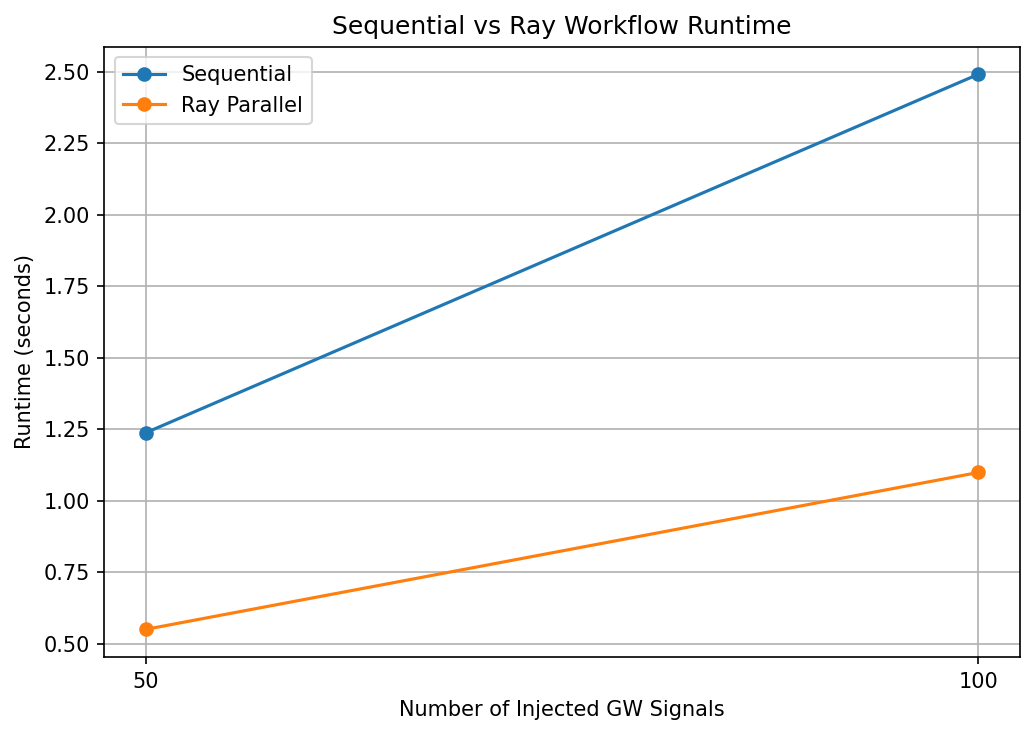

In [22]:
%matplotlib inline

import matplotlib.pyplot as plt

# Keep only results for 50 and 100 signals
filtered_results = [r for r in results if r[0] in [50, 100]]

print("Results:", filtered_results)

n_signals = [r[0] for r in filtered_results]
sequential_times = [r[1] for r in filtered_results]
ray_times = [r[2] for r in filtered_results]

plt.figure(figsize=(7, 5))

plt.plot(
    n_signals,
    sequential_times,
    "o-",
    label="Sequential"
)

plt.plot(
    n_signals,
    ray_times,
    "o-",
    label="Ray Parallel"
)

plt.xlabel("Number of Injected GW Signals")
plt.ylabel("Runtime (seconds)")
plt.title("Sequential vs Ray Workflow Runtime")

plt.xticks([50, 100])

plt.legend()
plt.grid()

plt.tight_layout()

# Save for GitLab README/results folder
plt.savefig(
    "runtime_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()